# Deep Learning: Image Classification with TensorFlow

Welcome to the Deep Learning module. When traditional machine learning algorithms plateau in performance, we bring in Neural Networks. They are incredibly powerful, but require much more manual architectural design.

In this notebook, we'll build a Multi-Layer Perceptron (MLP) from scratch using **TensorFlow and Keras** to classify images of handwritten digits.

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

plt.style.use('ggplot')

## 1. Load and Visualize the Image Data
Neural networks hate unscaled data. The digits dataset contains 8x8 pixel images with values ranging from 0 to 16. We MUST normalize these pixels down to a `0.0 - 1.0` scale so the network's gradients don't explode.

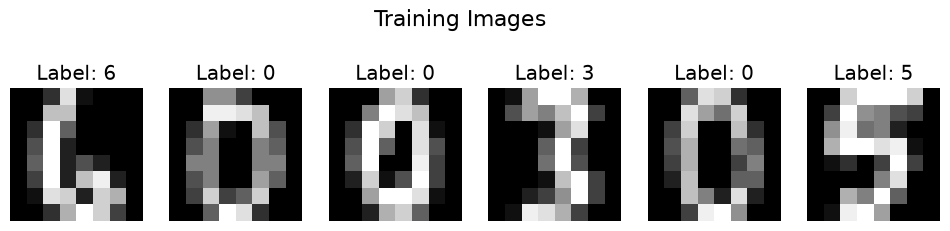

In [2]:
digits = load_digits()

# NORMALIZATION: Crucial step for Neural Networks
X = digits.data / 16.0  
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Let's visualize exactly what the neural network "sees"
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i in range(6):
    # Reshape the flat 64-length array back into an 8x8 image grid
    axes[i].imshow(X_train[i].reshape(8, 8), cmap='gray')
    axes[i].set_title(f'Label: {y_train[i]}')
    axes[i].axis('off')

plt.suptitle('Training Images', fontsize=16)
plt.show()

## 2. Designing the Neural Network Architecture
We are building a **Sequential** model. 
- **Hidden Layer 1**: 128 Neurons (ReLU activation). 
- **Dropout Layer**: Randomly turns off 20% of neurons during training to prevent the network from memorizing exact pixels (Overfitting prevention).
- **Hidden Layer 2**: 64 Neurons (ReLU).
- **Output Layer**: 10 Neurons (Softmax activation). This outputs a probability for each of the 10 possible digits (0-9).

In [3]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(128, activation='relu', input_shape=(64,)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

# Print the architectural blueprint of our network
model.summary()

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Training the Network
We train for 30 epochs, processing the data in batches of 32 images at a time.

In [4]:
print("Starting training loop...")
history = model.fit(X_train, y_train, 
                    epochs=30, 
                    batch_size=32, 
                    validation_data=(X_test, y_test), 
                    verbose=1)  # Set to 1 to see the live progress bar!
print("Training completed!")

Starting training loop...
Epoch 1/30


 1/45 ━━━━━━━━━━━━━━━━━━━━ 36s 826ms/step - accuracy: 0.1250 - loss: 2.3693

40/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4148 - loss: 2.0291   

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4426 - loss: 1.9832 - val_accuracy: 0.7722 - val_loss: 1.4425


Epoch 2/30


 1/45 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5000 - loss: 1.6360

... (104 outputs left out)

 1/45 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 1.0000 - loss: 0.0373

39/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9952 - loss: 0.0252 

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9944 - loss: 0.0272 - val_accuracy: 0.9861 - val_loss: 0.0815


Training completed!


## 4. Lifecycle Diagnostics (The Learning Curves)
The absolute most important part of Deep Learning is tracking the Learning Curves. If Training Loss goes down, but Validation Loss starts going up, your network is overfitting!


Final Unseen Test Accuracy: 98.61%

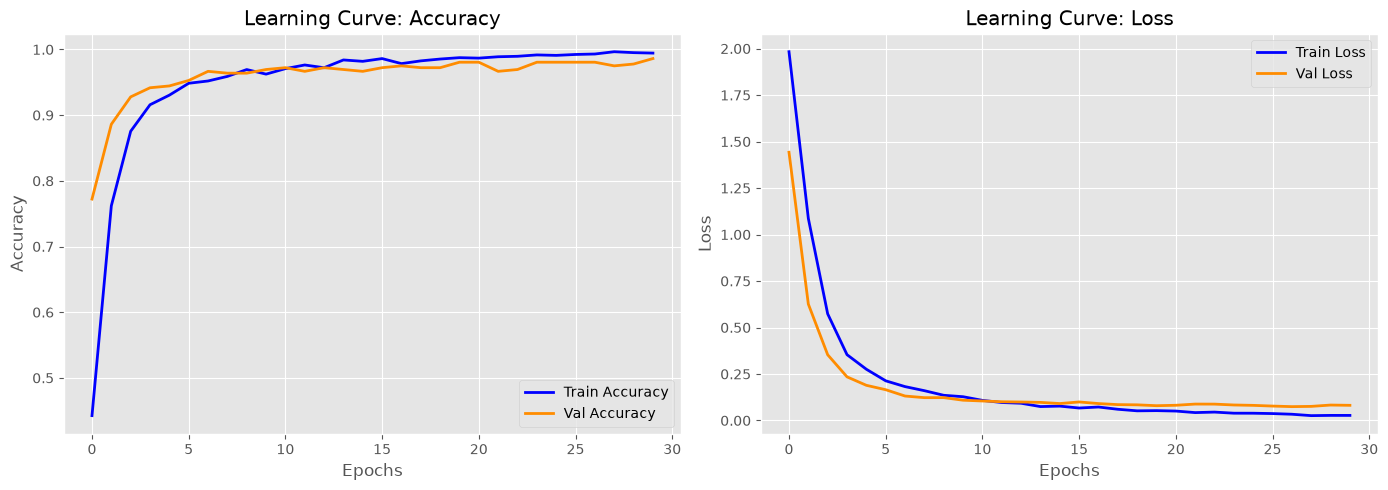

In [5]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nFinal Unseen Test Accuracy: {test_acc*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='blue', lw=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', color='darkorange', lw=2)
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Learning Curve: Accuracy')
axes[0].legend()

# Plot Loss
axes[1].plot(history.history['loss'], label='Train Loss', color='blue', lw=2)
axes[1].plot(history.history['val_loss'], label='Val Loss', color='darkorange', lw=2)
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].set_title('Learning Curve: Loss')
axes[1].legend()

plt.tight_layout()
plt.show()